# Exploratory Data Analysis

In [1]:
# Main libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Read data
USECOLS = [
    "vendor_id", "pickup_datetime",
    "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "trip_duration",
    "temperature_2m_c", "precipitation_mm", "rain_mm",
    "cloudcover", "cloudcover_low", "cloudcover_mid", "cloudcover_high",
    "windspeed_10m_km_h", "winddirection_10m",
]

DTYPES = {
    "vendor_id": "int8",
    "passenger_count": "int8",
    "pickup_longitude": "float32", "pickup_latitude": "float32",
    "dropoff_longitude": "float32", "dropoff_latitude": "float32",
    "trip_duration": "int32",
    "temperature_2m_c": "float32", "precipitation_mm": "float32", "rain_mm": "float32",
    "cloudcover": "float32", "cloudcover_low": "float32",
    "cloudcover_mid": "float32", "cloudcover_high": "float32",
    "windspeed_10m_km_h": "float32", "winddirection_10m": "float32",
}

def load(path):
    df = pd.read_csv(path, usecols=USECOLS, dtype=DTYPES,
                     parse_dates=["pickup_datetime"])
    return df

#### Quick overview
First, let's provide a quick overview of the columns in taxi_trips.csv, and what each one represents:
|column|description|
|------|-------|
|id|unique id for each taxi trip|
|vendor_id|TPEP provider, 1=CMT, 2=VTS|
|pickup_datetime|date and time when the meter was engaged|
|dropoff_datetime|date and time when the meter was disengaged|
|passenger_count|number of passangers|
|pickup_longitude|longitude where the meter was engaged|
|pickup_latitude|latitude where the meter was engaged|
|dropoff_longitude|longitude where the meter was disengaged|
|dropoff_latitude|latitude where the meter was disengaged|
|store_and_fwd_flag|if trip record was stored in vehicle (True) or if it was sent immediately to server (False)|
|trip_duration|total time the meter was engaged in seconds|
|temperature_2m_c|air temperature at 2 meters above ground|
|precipitation_mm|total precipitation of the preciding hour (rain, snow, etc)|
|rain_mm|Liquid precipitation in the preciding hour|
|cloudcover|Total cloud as an area fraction|
|cloudcover_low|Low level clouds and fog up to 2 km altitude|
|cloudcover_mid|Mid level clouds from 2 to 6 km altitude|
|cloudcover_high|High level clouds above 6km altitude|
|windspeed_10m_km_h|Wind speed at 10 meters above ground|
|winddirection_10m|Wind direction at 10 meters above ground (degrees clockwise)|

When loading the data, we can drop `id`, `dropoff_datetime`, and `store_and_fwd_flag`, as they add no information about the trip. Dropoff datetime would only help if we didn't already have the trip duration.

In [3]:
TaxiTrips = load("taxi_trips.csv")
TaxiTrips.head()

,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,temperature_2m_c,precipitation_mm,rain_mm,cloudcover,cloudcover_low,cloudcover_mid,cloudcover_high,windspeed_10m_km_h,winddirection_10m
0,2,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,455,6.400000,0.2,0.2,100.0,100.0,100.0,7.0,21.100000,70.0
1,1,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,663,28.799999,0.0,0.0,5.0,0.0,8.0,0.0,12.200000,251.0
2,2,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,2124,-7.600000,0.0,0.0,0.0,0.0,0.0,0.0,22.000000,272.0
3,2,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,429,7.900000,0.0,0.0,2.0,0.0,1.0,3.0,21.299999,177.0
4,2,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,435,4.700000,0.0,0.0,5.0,1.0,0.0,13.0,12.400000,22.0


## Dataset profile and data quality

We inspect dimensions, types, missingness, duplicates, and plausible ranges before interpreting patterns. Summary statistics use all rows; plots of high-volume observations use a reproducible sample where appropriate.

## Trip duration and time patterns

Trip duration is expected to be right-skewed, so we inspect it both on its original scale and after a log transformation. Pickup-time features reveal hourly, weekday, and monthly variation.

## Geography, weather, and relationships

We compare locations and estimate straight-line distance as a descriptive feature (not route distance). Associations are exploratory and do not establish causation.

In [4]:
# Dataset shape, dtypes, and missingness
print(f"Rows: {len(TaxiTrips):,} | Columns: {TaxiTrips.shape[1]}")
display(TaxiTrips.dtypes.rename("dtype").to_frame())

quality = pd.DataFrame({
    "missing_count": TaxiTrips.isna().sum(),
    "missing_percent": (TaxiTrips.isna().mean() * 100).round(3),
})
display(quality.sort_values("missing_count", ascending=False))
print(f"Exact duplicate rows: {TaxiTrips.duplicated().sum():,}")

# Flag records for investigation; do not discard them during EDA.
duration = TaxiTrips["trip_duration"]
coordinate_columns = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
]
in_nyc_bounds = (
    TaxiTrips["pickup_longitude"].between(-74.3, -73.6)
    & TaxiTrips["dropoff_longitude"].between(-74.3, -73.6)
    & TaxiTrips["pickup_latitude"].between(40.4, 41.0)
    & TaxiTrips["dropoff_latitude"].between(40.4, 41.0)
)
quality_flags = pd.Series({
    "non_positive_trip_duration": duration.le(0).sum(),
    "duration_over_3_hours": duration.gt(3 * 60 * 60).sum(),
    "passenger_count_outside_1_to_6": (~TaxiTrips["passenger_count"].between(1, 6)).sum(),
    "pickup_or_dropoff_outside_approx_nyc_bounds": (~in_nyc_bounds).sum(),
})
display(quality_flags.rename("row_count").to_frame())
print("Pickup date range:", TaxiTrips["pickup_datetime"].min(), "to", TaxiTrips["pickup_datetime"].max())

Rows: 1,458,644 | Columns: 17


,dtype
vendor_id,int8
pickup_datetime,datetime64[us]
passenger_count,int8
pickup_longitude,float32
pickup_latitude,float32
dropoff_longitude,float32
dropoff_latitude,float32
trip_duration,int32
temperature_2m_c,float32
precipitation_mm,float32


,missing_count,missing_percent
vendor_id,0,0.0
pickup_datetime,0,0.0
passenger_count,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,0,0.0
dropoff_latitude,0,0.0
trip_duration,0,0.0
temperature_2m_c,0,0.0
precipitation_mm,0,0.0


Exact duplicate rows: 7


,row_count
non_positive_trip_duration,0
duration_over_3_hours,2112
passenger_count_outside_1_to_6,65
pickup_or_dropoff_outside_approx_nyc_bounds,620


Pickup date range: 2016-01-01 00:00:17 to 2016-06-30 23:59:39


,trip_duration_minutes
count,1.458644e+06
mean,1.599154e+01
std,8.729053e+01
min,1.666667e-02
1%,1.450000e+00
5%,3.000000e+00
25%,6.616667e+00
50%,1.103333e+01
75%,1.791667e+01
90%,2.723333e+01


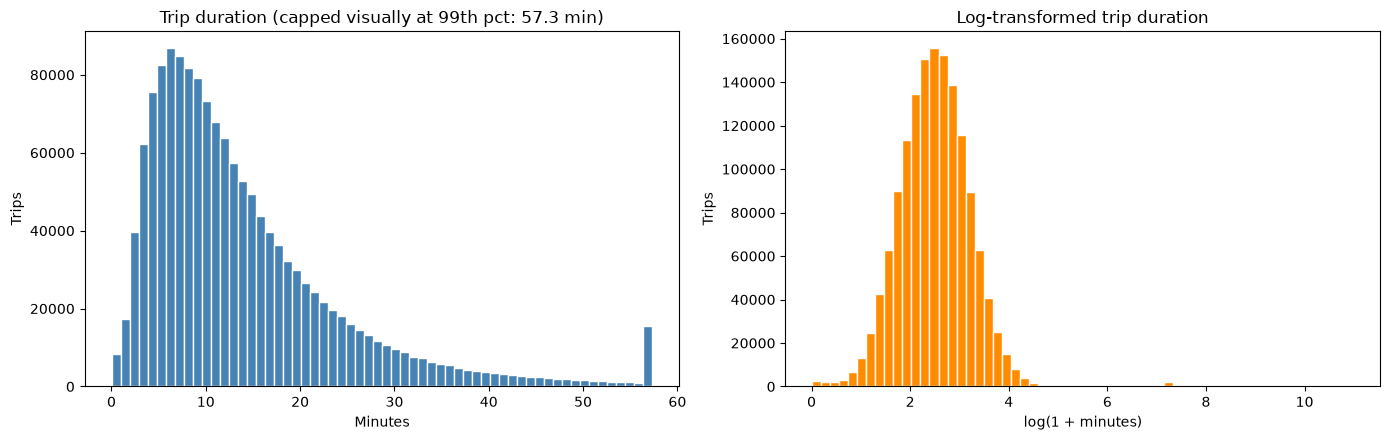

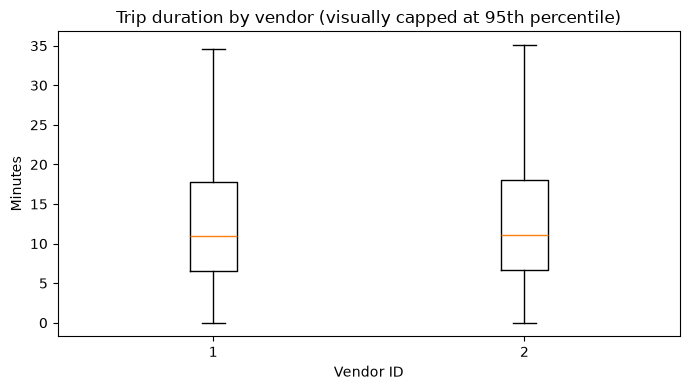

In [5]:
# Target distribution and robust summary statistics
duration_minutes = duration / 60
display(duration_minutes.describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).rename("trip_duration_minutes").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
upper_minutes = duration_minutes.quantile(.99)
axes[0].hist(duration_minutes.clip(upper=upper_minutes), bins=60, color="steelblue", edgecolor="white")
axes[0].set(title=f"Trip duration (capped visually at 99th pct: {upper_minutes:.1f} min)", xlabel="Minutes", ylabel="Trips")
axes[1].hist(np.log1p(duration_minutes.clip(lower=0)), bins=60, color="darkorange", edgecolor="white")
axes[1].set(title="Log-transformed trip duration", xlabel="log(1 + minutes)", ylabel="Trips")
plt.tight_layout()
plt.show()

# Typical duration by vendor; boxplots hide extreme tails for readability.
fig, ax = plt.subplots(figsize=(7, 4))
vendor_groups = [duration_minutes[TaxiTrips["vendor_id"].eq(v)].clip(upper=duration_minutes.quantile(.95)) for v in sorted(TaxiTrips["vendor_id"].dropna().unique())]
ax.boxplot(vendor_groups, tick_labels=[str(v) for v in sorted(TaxiTrips["vendor_id"].dropna().unique())], showfliers=False)
ax.set(title="Trip duration by vendor (visually capped at 95th percentile)", xlabel="Vendor ID", ylabel="Minutes")
plt.tight_layout()
plt.show()

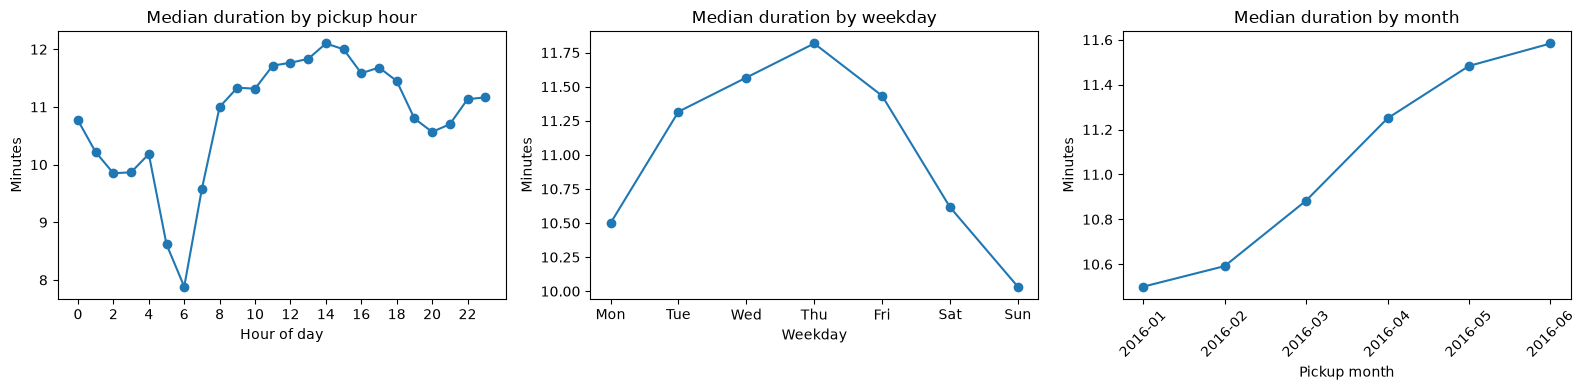

Trip counts by month:


,trip_count
pickup_month,
2016-01,229707
2016-02,238300
2016-03,256189
2016-04,251645
2016-05,248487
2016-06,234316


In [6]:
# Pickup time patterns. Weekday: Monday=0 through Sunday=6.
time_data = TaxiTrips.assign(
    duration_minutes=duration_minutes,
    pickup_hour=TaxiTrips["pickup_datetime"].dt.hour,
    pickup_weekday=TaxiTrips["pickup_datetime"].dt.dayofweek,
    pickup_month=TaxiTrips["pickup_datetime"].dt.to_period("M").astype(str),
)
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hourly = time_data.groupby("pickup_hour")["duration_minutes"].median()
weekday = time_data.groupby("pickup_weekday")["duration_minutes"].median()
monthly = time_data.groupby("pickup_month")["duration_minutes"].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hourly.plot(ax=axes[0], marker="o")
axes[0].set(title="Median duration by pickup hour", xlabel="Hour of day", ylabel="Minutes", xticks=range(0, 24, 2))
weekday.plot(ax=axes[1], marker="o")
axes[1].set(title="Median duration by weekday", xlabel="Weekday", ylabel="Minutes", xticks=range(7), xticklabels=weekday_names)
monthly.plot(ax=axes[2], marker="o")
axes[2].set(title="Median duration by month", xlabel="Pickup month", ylabel="Minutes")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Trip counts by month:")
display(time_data.groupby("pickup_month").size().rename("trip_count").to_frame())

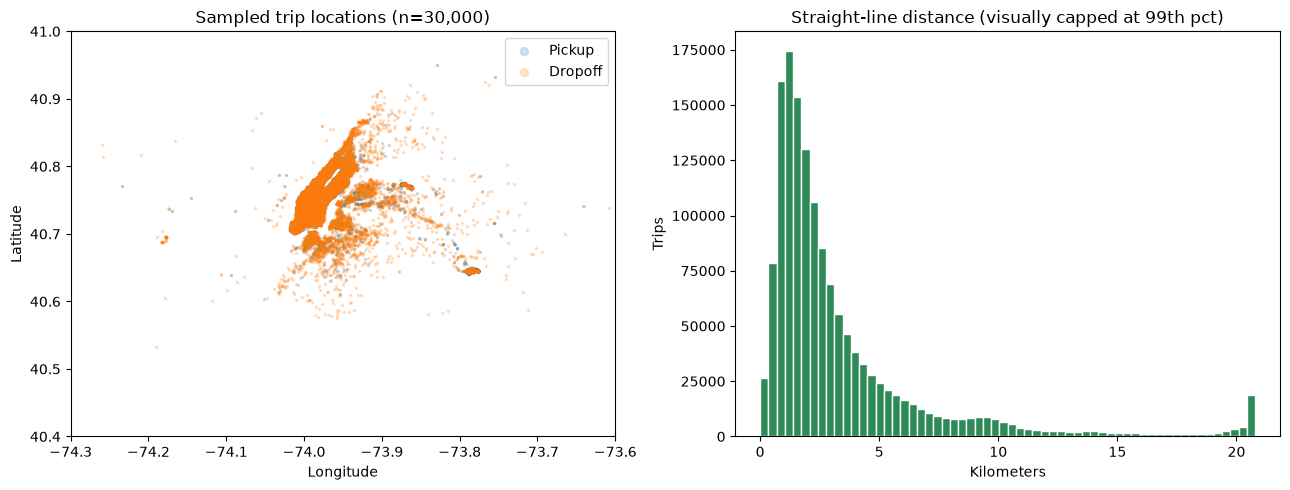

,straight_line_distance_km,duration_minutes
count,1458644.00,1458644.00
mean,3.44,15.99
std,4.30,87.29
min,0.00,0.02
50%,2.09,11.03
90%,7.63,27.23
99%,20.79,57.33
max,1240.91,58771.37


,pearson_r_with_log_duration
straight_line_distance_km,0.573595
temperature_2m_c,0.042549
cloudcover_high,0.015914
rain_mm,0.002290
cloudcover,0.001079
precipitation_mm,0.000697
cloudcover_mid,-0.000683
cloudcover_low,-0.002894
winddirection_10m,-0.011579
windspeed_10m_km_h,-0.012400


,count,median,mean
precipitation_mm,,,
0,1276386,11.033333,16.002557
>0-0.1,0,NaN,NaN
>0.1-1,142513,11.000000,16.020799
>1-5,38081,11.166667,15.598038
>5 mm,1664,10.733333,14.038211


In [7]:
# Approximate straight-line distance using the haversine formula (km).

lat1 = np.radians(TaxiTrips["pickup_latitude"].to_numpy())
lat2 = np.radians(TaxiTrips["dropoff_latitude"].to_numpy())
dlat = lat2 - lat1
dlon = np.radians(TaxiTrips["dropoff_longitude"].to_numpy() - TaxiTrips["pickup_longitude"].to_numpy())
haversine = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
distance_km = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(haversine, 0, 1)))

rng = np.random.default_rng(42)
sample_size = min(30_000, len(TaxiTrips))
sample_idx = rng.choice(len(TaxiTrips), size=sample_size, replace=False)
geo_sample = TaxiTrips.iloc[sample_idx]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(geo_sample["pickup_longitude"], geo_sample["pickup_latitude"], s=2, alpha=.2, label="Pickup")
axes[0].scatter(geo_sample["dropoff_longitude"], geo_sample["dropoff_latitude"], s=2, alpha=.2, label="Dropoff")
axes[0].set(title=f"Sampled trip locations (n={sample_size:,})", xlabel="Longitude", ylabel="Latitude", xlim=(-74.3, -73.6), ylim=(40.4, 41.0))
axes[0].legend(markerscale=4)
distance_series = pd.Series(distance_km, index=TaxiTrips.index)
axes[1].hist(distance_series.clip(upper=distance_series.quantile(.99)), bins=60, color="seagreen", edgecolor="white")
axes[1].set(title="Straight-line distance (visually capped at 99th pct)", xlabel="Kilometers", ylabel="Trips")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"straight_line_distance_km": distance_series, "duration_minutes": duration_minutes}).describe(percentiles=[.5, .9, .99]).round(2))

# Correlations with log duration reduce the influence of the very long-trip tail.
weather_columns = [
    "temperature_2m_c", "precipitation_mm", "rain_mm", "cloudcover",
    "cloudcover_low", "cloudcover_mid", "cloudcover_high",
    "windspeed_10m_km_h", "winddirection_10m",
]
association_data = TaxiTrips[weather_columns].copy()
association_data["log_duration"] = np.log1p(duration.clip(lower=0))
association_data["straight_line_distance_km"] = distance_series
display(association_data.corr(numeric_only=True)[["log_duration"]].drop(index="log_duration").sort_values("log_duration", ascending=False).rename(columns={"log_duration": "pearson_r_with_log_duration"}))

# Weather values and target relationship are easiest to interpret with binned medians.
rain = TaxiTrips["precipitation_mm"]
rain_bins = pd.cut(rain, bins=[-0.001, 0, 0.1, 1, 5, np.inf], labels=["0", ">0-0.1", ">0.1-1", ">1-5", ">5 mm"])
rain_summary = time_data.groupby(rain_bins, observed=False)["duration_minutes"].agg(["count", "median", "mean"])
display(rain_summary)

## Initial findings and next steps

- The file contains **1,458,644 trips** from January through June 2016. The analyzed columns have no missing values, but **7 exact duplicate rows** were found.
- Trip duration is strongly right-skewed: the median is about **11.0 minutes**, the 99th percentile is **57.3 minutes**, and the maximum is over **40 days**. Investigate very long trips and duplicate records before model training; do not treat these flags as automatic deletion rules.
- **620 trips** have at least one endpoint outside the approximate NYC bounds, and the longest straight-line distance is over **1,200 km**. These may represent coordinate/data errors and should be checked alongside the corresponding raw rows.
- Straight-line distance has a moderate positive correlation with log duration (**Pearson r about 0.57**). Weather correlations are small in this unadjusted analysis; median duration is similar across observed precipitation bins. Consider trip distance, pickup time, and other confounders before interpreting weather effects.

The monthly counts and temporal plots provide context for the six-month coverage. For a prediction workflow, decide on documented quality filters, derive time/location features, and evaluate on a time-based holdout to avoid optimistic random-split results.